#### *1.get unic ip ID . from the loge the request*
#### *2.get how many 200,300,400 error code*
#### *3.write the result to csv file*


In [27]:
import os

path = "C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop\\"

myfile = "mylog.log"

In [28]:
##1.Reads first 100 content using read mode

print(os.path.join(path,myfile))

with open(os.path.join(path,myfile)) as f:
    content  = f.read()
    print(content[:100]) 

C:\Users\Yesu\OneDrive\Documents\Desktop\mylog.log
http 2021-10-05T23:55:13.192364Z app/DAS-G1-APS4-int-elb/3bbf8f4d5647499d 10.73.146.189:40824 10.73.


In [29]:
##2.Reads first line content using read mode

with open(os.path.join(path,myfile)) as f:
    for each in f:
        print(each)
        break 

http 2021-10-05T23:55:13.192364Z app/DAS-G1-APS4-int-elb/3bbf8f4d5647499d 10.73.146.189:40824 10.73.132.17:80 0.000 0.001 0.000 304 304 337 266 "GET http://das-000-int.geo.g1.genprim.com:80/workspaces/00000000-0000-0000-0000-000000000000/voice_tests/vhc/version_05/src-gen-20181103002947/version_05.scxml HTTP/1.1" "-" - - arn:aws:elasticloadbalancing:ap-southeast-1:361190373704:targetgroup/DAS-G1-APS4-tg-dasg/cd94c4492084142e "Root=1-615ce5e1-3ac891bd02d60b2d6bb7877b" "-" "-" 0 2021-10-05T23:55:13.190000Z "forward" "-" "-" "10.73.132.17:80" "304" "-" "-"



In [30]:
##3.need create list so than acesss a user_id and status code from log file

import os

path = "C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop"
myfile = "mylog.log"

with open(os.path.join(path,myfile)) as f:
    for each_line in f:
        print(each_line.split(" "))
        break 

['http', '2021-10-05T23:55:13.192364Z', 'app/DAS-G1-APS4-int-elb/3bbf8f4d5647499d', '10.73.146.189:40824', '10.73.132.17:80', '0.000', '0.001', '0.000', '304', '304', '337', '266', '"GET', 'http://das-000-int.geo.g1.genprim.com:80/workspaces/00000000-0000-0000-0000-000000000000/voice_tests/vhc/version_05/src-gen-20181103002947/version_05.scxml', 'HTTP/1.1"', '"-"', '-', '-', 'arn:aws:elasticloadbalancing:ap-southeast-1:361190373704:targetgroup/DAS-G1-APS4-tg-dasg/cd94c4492084142e', '"Root=1-615ce5e1-3ac891bd02d60b2d6bb7877b"', '"-"', '"-"', '0', '2021-10-05T23:55:13.190000Z', '"forward"', '"-"', '"-"', '"10.73.132.17:80"', '"304"', '"-"', '"-"\n']


In [31]:
##4.need pick user_id[3] and status code[8] from log file

import os

path = "C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop"
myfile =  "mylog.log"

with open(os.path.join(path,myfile)) as f:
    for each_line in f:
        mylist = each_line.split(" ") #the spilted list assigned to  mylist(variable)

        ip,http_status = mylist[3],mylist[8] #stored in ip,http_status varible and Filtered
        print(http_status)
        print(ip)
        break 


304
10.73.146.189:40824


In [12]:
##5.to save and append this user_id and status code need store[] in varibale


import os
import csv

path = "C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop"
myfile =  "mylog.log"


ip = []
http_status = []



with open(os.path.join(path,myfile)) as f:
    for each_line in f:
        mylist = each_line.split(" ")
        ip.append(mylist[3])
        http_status.append(mylist[8])

    print(ip)
    print(http_status)


['10.73.146.189:40824', '10.73.146.189:40820', '10.73.146.189:40820', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.146.189:40820', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.145.224:34320', '10.73.146.189:40822', '10.73.146.189:40822', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.133.231:35848', '10.73.145.224:34322', '10.73.145.224:34322', '10.73.145.224:37428', '10.73.145.224:34322', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132.212:36528', '10.73.132

In [13]:
## 5. Count frequency for IP and HTTP status

def frequency(mylist):
    mydict = {}

    for each in mylist:
        if each not in mydict:
            mydict[each] = 1
        else:
            mydict[each] += 1

    return mydict


rest1 = frequency(ip)
rest2 = frequency(http_status)

print("IP Frequency:", rest1)
print("HTTP Status Frequency:", rest2)



IP Frequency: {'10.73.146.189:40824': 1, '10.73.146.189:40820': 3, '10.73.145.224:34320': 80, '10.73.146.189:40822': 2, '10.73.133.231:35848': 44, '10.73.145.224:34322': 21, '10.73.145.224:37428': 6, '10.73.132.212:36528': 41, '10.73.144.159:53100': 4, '10.73.133.204:41548': 96, '10.73.144.159:53104': 1, '10.73.144.159:53102': 1, '10.73.132.5:45692': 38, '10.73.132.212:36756': 6}
HTTP Status Frequency: {'304': 186, '404': 43, '200': 115}


In [14]:
##6.need save in csv file 

import os
import csv

def write_to_csv(mydict, filename, column_name):
    with open(os.path.join(path, filename), "w", newline="") as f:
        writer = csv.writer(f)

        writer.writerow(["Sno", column_name, "Frequency"])

        for sno, (item, count) in enumerate(mydict.items(), start=1):
            writer.writerow([sno, item, count])


rest1 = frequency(ip)
rest2 = frequency(http_status)

print("IP frequency:", rest1)
print("HTTP status frequency:", rest2)

write_to_csv(rest1, "ip_frequency.csv", "IP_Address")
write_to_csv(rest2, "http_status_frequency.csv", "HTTP_Status")

print("CSV files created successfully")


IP frequency: {'10.73.146.189:40824': 1, '10.73.146.189:40820': 3, '10.73.145.224:34320': 80, '10.73.146.189:40822': 2, '10.73.133.231:35848': 44, '10.73.145.224:34322': 21, '10.73.145.224:37428': 6, '10.73.132.212:36528': 41, '10.73.144.159:53100': 4, '10.73.133.204:41548': 96, '10.73.144.159:53104': 1, '10.73.144.159:53102': 1, '10.73.132.5:45692': 38, '10.73.132.212:36756': 6}
HTTP status frequency: {'304': 186, '404': 43, '200': 115}
CSV files created successfully


In [15]:
##6.need read and visul data 

import pandas as pd

df = pd.read_csv("C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop\\ip_frequency.csv")
df

,Sno,IP_Address,Frequency
0,1,10.73.146.189:40824,1
1,2,10.73.146.189:40820,3
2,3,10.73.145.224:34320,80
3,4,10.73.146.189:40822,2
4,5,10.73.133.231:35848,44
5,6,10.73.145.224:34322,21
6,7,10.73.145.224:37428,6
7,8,10.73.132.212:36528,41
8,9,10.73.144.159:53100,4
9,10,10.73.133.204:41548,96


In [16]:
data = df.copy()
print(data)

    Sno           IP_Address  Frequency
0     1  10.73.146.189:40824          1
1     2  10.73.146.189:40820          3
2     3  10.73.145.224:34320         80
3     4  10.73.146.189:40822          2
4     5  10.73.133.231:35848         44
5     6  10.73.145.224:34322         21
6     7  10.73.145.224:37428          6
7     8  10.73.132.212:36528         41
8     9  10.73.144.159:53100          4
9    10  10.73.133.204:41548         96
10   11  10.73.144.159:53104          1
11   12  10.73.144.159:53102          1
12   13    10.73.132.5:45692         38
13   14  10.73.132.212:36756          6


In [17]:
data.drop("Sno",axis=1,inplace=True)

In [18]:
data

,IP_Address,Frequency
0,10.73.146.189:40824,1
1,10.73.146.189:40820,3
2,10.73.145.224:34320,80
3,10.73.146.189:40822,2
4,10.73.133.231:35848,44
5,10.73.145.224:34322,21
6,10.73.145.224:37428,6
7,10.73.132.212:36528,41
8,10.73.144.159:53100,4
9,10.73.133.204:41548,96


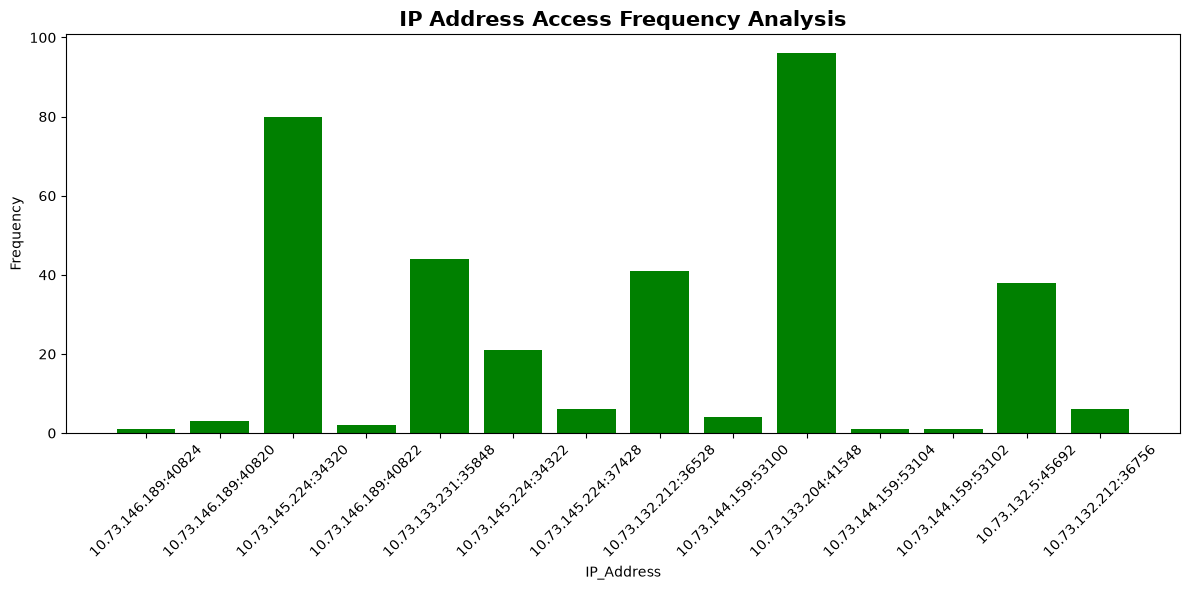

In [42]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.bar(data["IP_Address"], data["Frequency"],color="green")
plt.title("IP Address Access Frequency Analysis",fontsize=15,fontweight="bold")
plt.xlabel("IP_Address")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [44]:

import pandas as pd

df1 = pd.read_csv("C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop\\http_status_frequency.csv")
df1

,Sno,HTTP_Status,Frequency
0,1,304,186
1,2,404,43
2,3,200,115


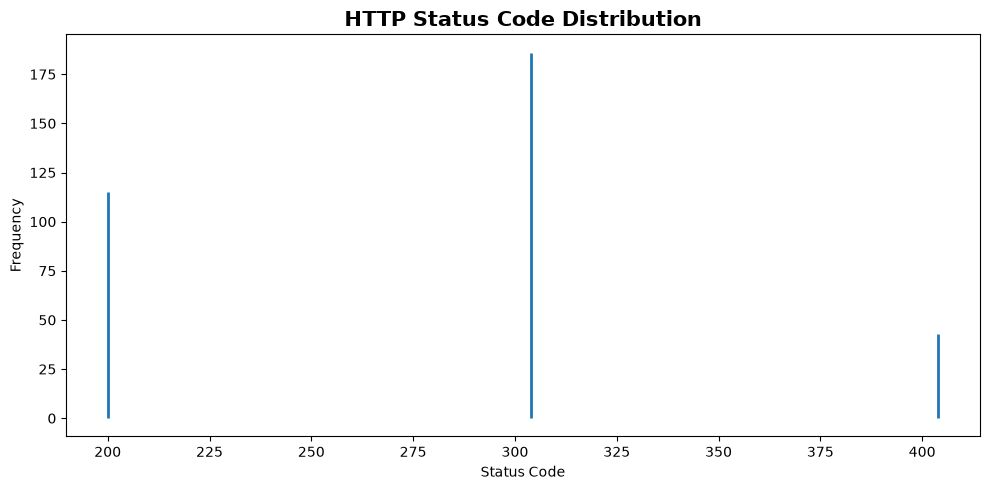

In [53]:
plt.figure(figsize=(10, 5))

plt.vlines(
    x=df1["HTTP_Status"],
    ymin=0,
    ymax=df1["Frequency"],
    linewidth=2
)

plt.title("HTTP Status Code Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Status Code")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()